# All-called aggregate contact map (MIA-Jet)

Aggregate observed/expected contact map over all MIA-Jet calls for the sample defined in `CONFIG` below.

In [1]:
import sys
sys.path.append('..')

import os
import yaml
import numpy as np
import pandas as pd
import bioframe as bf

from utils.plotting import plot_n_hic, genomic_labels
from func_pileup import generate_bed_2, get_pileups_dynamic_resolution, remove_and_resize_square_stacks

In [2]:
CONFIG = """
zebrafish-embryo_sperm_hic_Wike-2021_4DNFI4P145EM_z11:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/zebrafish-embryo_sperm_hic_Wike-2021_4DNFI4P145EM_z11.hic"
    genome: "danRer11"
    norm: "KR"
    res: "50000"
    exp: "hic"
    mcool: "/nfs/turbo/umms-minjilab/downloaded_data/zebrafish-embryo_sperm_hic_Wike-2021_4DNFI4P145EM_z11.ice.mcool"
    win: "6000000"
    chroms: "all"
    compartment: "False"
    angle_turbulence: "0.75"
    adj_nondec: "False" # Disable consistency
    q_val: "0.5"
    root_within: "6"
    extra_args:
      - "--diagnostic_plots"
"""
attributes = next(iter(yaml.safe_load(CONFIG).values()))

In [3]:
# Analysis parameters
output_name = "v2.0.3"
save_path = "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/revision2"
os.makedirs(save_path, exist_ok=True)

data_type = "oe"
expected_stack_size = 100

hic_file = attributes["file"]
data_name = os.path.splitext(os.path.basename(hic_file))[0]
resolution = int(attributes["res"])
genome = attributes["genome"]

# Standardize normalization to "VC_SQRT" for hicstraw compatibility (unless "NONE" or "VC")
normalization = attributes["norm"] if attributes["norm"] in ("NONE", "VC") else "VC_SQRT"

# compartment is "False", so the MIA-Jet output name carries no white q-value
q_val_str = f"q_val_{attributes['q_val']}"

# Load MIA-Jet summary and expanded tables
res_label = genomic_labels(resolution)
folder = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{data_name}_chr_combined_{res_label}"
prefix = f"{data_name}_chr_combined_"
suffix = f"_{res_label}_summary_table.csv"
fname = next(f for f in os.listdir(folder) if f.startswith(prefix) and f.endswith(suffix) and q_val_str in f)
result_type = fname[len(prefix):-len(suffix)]
print(f"* Selected MIA-Jet summary table: {fname}")

miajet_table = pd.read_csv(os.path.join(folder, fname), comment="#")
miajet_positions = pd.read_csv(os.path.join(folder, f"{prefix}{result_type}_{res_label}_expanded_table.csv"), comment="#")

# Keep only chromosomes present in the genome's chrom sizes
chrom_sizes = bf.fetch_chromsizes(genome, as_bed=True)
miajet_table = miajet_table[miajet_table["chrom"].isin(chrom_sizes["chrom"])]

* Selected MIA-Jet summary table: zebrafish-embryo_sperm_hic_Wike-2021_4DNFI4P145EM_z11_chr_combined_q_val_0.5_50Kb_summary_table.csv


Retrieving pileups: 100%|██████████| 656/656 [00:13<00:00, 48.70it/s]


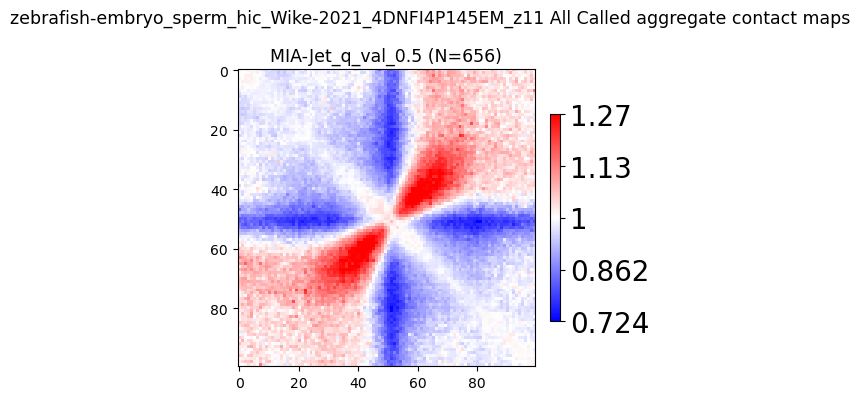

In [4]:
# Pileups over all called jets
bed_df = generate_bed_2(miajet_table, miajet_positions, eps=500e3, fraction=1.5)
stack, df_stack, _ = get_pileups_dynamic_resolution(
    hic_file=hic_file,
    bed_df_in=bed_df,
    expected_stack_size=expected_stack_size,
    chrom_sizes=chrom_sizes,
    data_type=data_type,
    normalization=normalization,
    sort=True,
    verbose=True
)
# Remove centromeres and resize square stacks
stack, df_stack = remove_and_resize_square_stacks(stack, df_stack, expected_stack_size)

a = np.mean(stack, axis=0)
agg_map = [a]
vmaxes = [np.percentile(a, 99) if np.percentile(a, 99) > np.nanmin(a) else np.nanmax(a)]
titles = [f"MIA-Jet_{result_type} (N={len(df_stack)})"]

# Diverging colormap centered at 1 for observed/expected
cmap = "bwr"
vcenter = 1

plot_n_hic(
        agg_map,
        suptitle=f"{data_name} All Called aggregate contact maps",
        resolution=None,
        cmap_label=None,
        titles=titles,
        cmap=cmap,
        vcenter=vcenter,
        standardize_cbar=True,
        show=True,
        vmax=vmaxes,
        ppr=4,
        # savepath=f"{save_path}/{data_name}_{resolution}_MIA-Jet_{result_type}_all_agg_map-{data_type}.png",
        cbar_fontsize=20,
    )